# Shorter EIGER scans — self-calibration from each dataset

**Question:** how much data can we remove while still extracting a useful correction from that same dataset? Detector response may vary unpredictably between acquisitions; no previously fitted detector correction file is loaded or transferred here.

Each original scan and each mimic subset independently runs **selected-frame aggregation → self-consistency fit → new pixel/sensor divisor and bad-pixel mask → corrected 1D integration**. Source-angle gains are also fitted from that subset alone and applied by default, matching the extraction approach. Geometry, physical-model parameters, fitting settings and the output grid are shared; fitted corrections are not. Even the full reference is refitted from scratch.

Scans **100599, 100601, 100603, 100605, 100607, 100609** have 3608 raw frames, 41 groups spanning approximately 0–80°, 88 frames/group and about 63 minutes wall time. Nonuniform motor spacings range from approximately 8.747° initially to 1.206° finally.

| Experiment | Selection |
|---|---|
| Exposure ladder | First 44 / 22 / 11 frames at all 41 positions |
| Every-second ladder | Every 2nd sorted position; both offsets |
| Protected every-third ladder | All positions through 15° motor angle, plus every 3rd position; all offsets |
| Motor stop | Mean motor angle ≤70° / ≤60°, with encoder tolerance |
| Combined | Every 2nd position and first 44 frames/group |
| Drift control | Spread 22 frames per group instead of first 22 |

All patterns use the same **fixed 0.05° diffraction-2θ bins** by default. Every-third hybrids retain 15–16 positions (37–39% of frames). Inspect actual coverage, fitting support, inferred divisors and corrected patterns together. Angular coverage alone does not guarantee enough repeated observations to identify a detector map. Failed fits are reported, never replaced with an old correction or silently relaxed thresholds.

**Limitations:** self-consistency is not independent validation or proof of a stable/accurate correction. A fit can absorb sample/model errors, and a response that changes *within* a scan violates the static-map assumption. The full-scan fit is a comparison reference, not ground truth. Subsets overlap it, and source gains are in-sample nuisance estimates; full-range use beyond the fitting Q range is extrapolation. Poisson sigmas exclude fitted-map, source-gain, I0 and model uncertainty and bin covariance. No display rescaling or background subtraction changes the exported patterns.

Beamline inputs and the original extraction notebook remain unchanged. Set `RUN_INTEGRATIONS=True` only when ready for the full set of fresh fits.

In [35]:
from pathlib import Path
from datetime import datetime
from dataclasses import replace
import importlib
import json
import sys
import time

import h5py
import hdf5plugin  # Registers compression filters for read-only beamline data.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = Path.cwd().resolve()
while REPO != REPO.parent and not (REPO / 'eiger_workflow.py').exists():
    REPO = REPO.parent
if not (REPO / 'eiger_workflow.py').exists():
    raise FileNotFoundError('Start Jupyter in the repository or a subdirectory')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
import eiger_workflow as workflow
import short_scan_tools as short
importlib.reload(short)

SCAN_NUMBERS = tuple(range(100599, 100610, 2))
DATA_DIRECTORY = Path('/dls/i15-1/data/2026/cm44163-4')
# Geometry only: no previously fitted detector correction file is loaded.
GEOMETRY_PATH = REPO / 'data' / 'i15-1-100579_2026-10-15_20-37-08_eiger_goniometer_calibration.json'
GEOMETRY_CONFIG = json.loads(GEOMETRY_PATH.read_text())
POLARIZATION_FACTOR = 0.95
SENSOR_DENSITY_G_CM3 = 6.2
FIT_SETTINGS = {
    'q_range': [200., 400.], 'npt': 800, 'iterations': 10,
    'fit_frame_gains': True, 'fractional_floor': 0.003, 'reject_z': 5.,
    'minimum_observations': 8, 'shrink_weight': 300., 'frame_prior_sigma': 0.01,
}
APPLY_SELF_FITTED_SOURCE_GAINS = True  # Learned anew from each subset; never transferred.
ANGLE_TOLERANCE_DEG = 0.001
TWO_THETA_STEP_DEG = 0.05
TWO_THETA_MAX_DEG = None
KEEP_LOW_MOTOR_DEG = 15.
RAW_SATURATION = 1e7
MIN_PIXEL_SPLIT_COUNT = 100
METRIC_INTERVALS = {'all': (0., 180.), 'low': (0., 30.),
                    'middle': (30., 60.), 'high': (60., 180.)}
RUN_INTEGRATIONS = True  # Enables fresh fitting AND integration: potentially expensive.
WRITE_OUTPUTS = True
RUN_DIRECTORY = REPO / 'outputs' / ('self_fit_short_scan_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))

CUTS = [short.Cut('full')]
for fraction, label in ((0.5, '44'), (0.25, '22'), (0.125, '11')):
    CUTS.append(short.Cut(f'first_{label}', frame_fraction=fraction))
for stride in (2, 3):
    for offset in range(stride):
        protected_max = KEEP_LOW_MOTOR_DEG if stride == 3 else None
        suffix = '_keep_low' if protected_max is not None else ''
        CUTS.append(short.Cut(f'angle_every_{stride}_offset_{offset}{suffix}',
                              angle_stride=stride, angle_offset=offset,
                              keep_motor_below=protected_max))
CUTS.extend([
    short.Cut('motor_stop_70', motor_max=70.),
    short.Cut('motor_stop_60', motor_max=60.),
    short.Cut('angle_every_2_first_44', angle_stride=2, frame_fraction=0.5),
    short.Cut('spread_22', frame_fraction=0.25, frame_mode='spread'),
])
assert len({cut.name for cut in CUTS}) == len(CUTS)
assert CUTS[0].name == 'full', 'Fit the full reference first'
print('Self-calibration: fresh divisor, bad-pixel mask and source gains for EVERY cut')
print('Output step:', TWO_THETA_STEP_DEG, 'degrees; fits:', len(CUTS), 'per scan')
print('Every-third cuts retain all motor groups through', KEEP_LOW_MOTOR_DEG, 'degrees')
print('Fits/integrations enabled:', RUN_INTEGRATIONS)
print('New output directory:', RUN_DIRECTORY)

Self-calibration: fresh divisor, bad-pixel mask and source gains for EVERY cut
Output step: 0.05 degrees; fits: 13 per scan
Every-third cuts retain all motor groups through 15.0 degrees
Fits/integrations enabled: True
New output directory: /dls/science/users/fer45166/eiger-correction/outputs/self_fit_short_scan_20261028_175206_907057


## 1. Metadata-only selection plan

Groups are frozen from the full scan using the extraction notebook's minimum-anchored 0.001° tolerance. A fraction is rounded down to a whole frame (minimum one); actual counts and summed-I0 fractions are reported. The retained group's geometry is recomputed from **only the retained motor readings**, with no I0 weighting.

`first` takes the earliest frames **at each motor position**; `spread` and `random` sample throughout that position's acquisition. These are selection simulations, not necessarily a chronological prefix of a multi-pass scan. The plot below shows raw-frame order to make that distinction visible. A stop includes the nominal boundary group with encoder-tolerance allowance.

**Time is only a proxy:** wall duration × retained-frame fraction includes motion/overhead incorrectly. Fewer frames at every angle may retain most motor overhead; fewer motor positions may save it. The notebook does not claim an exact acquisition speedup, and summed I0 is an exposure/monitor proxy, not a time measurement.

,scan,cut,groups,frames,frame_fraction,i0_fraction,motor_min_deg,motor_max_deg,full_wall_minutes,proportional_time_proxy_minutes
0,i15-1-100599,full,41,3608,1.000000,1.000000,0.0,80.000030,62.900267,62.900267
1,i15-1-100599,first_44,41,1804,0.500000,0.499967,0.0,80.000030,62.900267,31.450133
2,i15-1-100599,first_22,41,902,0.250000,0.249979,0.0,80.000030,62.900267,15.725067
3,i15-1-100599,first_11,41,451,0.125000,0.125005,0.0,79.999975,62.900267,7.862533
4,i15-1-100599,angle_every_2_offset_0,21,1848,0.512195,0.512213,0.0,80.000030,62.900267,32.217210
...,...,...,...,...,...,...,...,...,...,...
73,i15-1-100609,angle_every_3_offset_2_keep_low,15,1320,0.365854,0.365977,0.0,77.575405,62.854767,22.995646
74,i15-1-100609,motor_stop_70,33,2904,0.804878,0.805005,0.0,69.975180,62.854767,50.590422
75,i15-1-100609,motor_stop_60,25,2200,0.609756,0.609685,0.0,58.881881,62.854767,38.326077
76,i15-1-100609,angle_every_2_first_44,21,924,0.256098,0.256110,0.0,79.999975,62.854767,16.096952


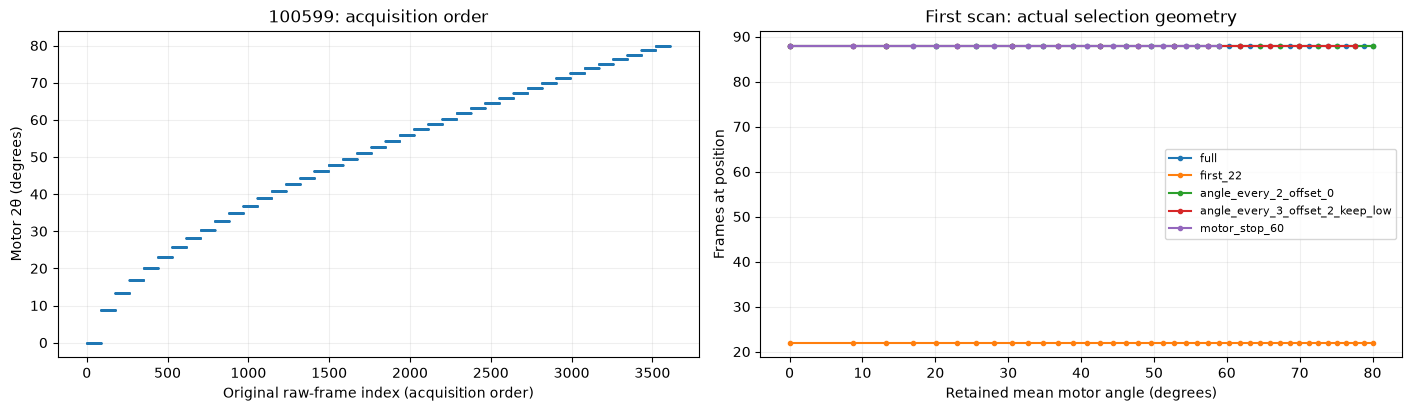

In [36]:
scans, calibrations, groups_by_scan = {}, {}, {}
plan_rows = []
for number in SCAN_NUMBERS:
    scan = workflow.load_scan(DATA_DIRECTORY / f'i15-1-{number}.nxs')
    groups = short.angle_groups(scan.angles, ANGLE_TOLERANCE_DEG)
    boundary, _ = workflow.detector_layout(scan.shape)
    # Geometry-only preflight: native/boundary masks, NO long-scan fitted bad pixels.
    preview_masks = {'base_mask': scan.native_mask | boundary,
                     'bad_pixel_mask': np.zeros(scan.shape, dtype=bool)}
    scans[number], calibrations[number], groups_by_scan[number] = scan, preview_masks, groups
    plan_rows.extend(short.selection_summary(scan, groups, CUTS, ANGLE_TOLERANCE_DEG))
plan = pd.DataFrame(plan_rows)
display(plan)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
number = SCAN_NUMBERS[0]
scan, groups = scans[number], groups_by_scan[number]
axes[0].plot(np.arange(len(scan.angles)), scan.angles, '.', ms=1.5)
axes[0].set(xlabel='Original raw-frame index (acquisition order)', ylabel='Motor 2θ (degrees)',
            title=f'{number}: acquisition order')
for name in ('full', 'first_22', 'angle_every_2_offset_0', 'angle_every_3_offset_2_keep_low', 'motor_stop_60'):
    cut = next(cut for cut in CUTS if cut.name == name)
    selection = short.select_groups(scan.angles, groups, cut, ANGLE_TOLERANCE_DEG)
    axes[1].plot([scan.angles[m].mean() for m in selection.values()],
                 [len(m) for m in selection.values()], '.-', label=name)
axes[1].set(xlabel='Retained mean motor angle (degrees)', ylabel='Frames at position',
            title='First scan: actual selection geometry')
axes[1].legend(fontsize=8)
for axis in axes:
    axis.grid(alpha=0.2)
plt.show()

## 2. Establish one fixed-step grid for all scans and cuts

Full-group geometry and **native/boundary masks only** determine the common maximum; no detector counts or fitted maps are read. The upper edge is rounded up to a multiple of `TWO_THETA_STEP_DEG`. Integration uses this same range and bin count even for motor stops. Each fitted subset can subsequently mask additional pixels; its actual post-fit support is audited separately.

Changing output step changes resolution/noise per bin; keep it fixed when judging acquisition cuts. The default 0.05° is a comparison grid, not a claim about instrumental resolution.

In [37]:
maxima = []
for number in SCAN_NUMBERS:
    scan, calibration, groups = scans[number], calibrations[number], groups_by_scan[number]
    grouped_metadata = replace(scan,
        angles=np.array([scan.angles[m].mean() for m in groups]),
        i0=np.array([scan.i0[m].sum() for m in groups]))
    model = workflow.PhysicalModel(GEOMETRY_CONFIG, grouped_metadata,
                                   POLARIZATION_FACTOR, SENSOR_DENSITY_G_CM3)
    model.vertical_check()
    mask = calibration['base_mask']  # Acquisition/layout only, not a prior fitted mask.
    maxima.append(workflow.theta_range_for_scan(grouped_metadata, model, mask,
                                                theta_max=TWO_THETA_MAX_DEG)[1])
    del model
THETA_RANGE, THETA_NPT, THETA_EDGES = short.fixed_theta_grid(max(maxima), TWO_THETA_STEP_DEG)
THETA_CENTRES = (THETA_EDGES[:-1] + THETA_EDGES[1:]) / 2
np.testing.assert_allclose(np.diff(THETA_EDGES), TWO_THETA_STEP_DEG, rtol=0, atol=1e-12)
print('Common fixed-step grid:', THETA_RANGE, 'degrees;', THETA_NPT, 'bins')
print('Exact requested step:', TWO_THETA_STEP_DEG, 'degrees')
print('Full-scan pixel-centre maxima:', dict(zip(SCAN_NUMBERS, maxima)))

Common fixed-step grid: (0.0, 87.15) degrees; 1743 bins
Exact requested step: 0.05 degrees
Full-scan pixel-centre maxima: {100599: 87.1330181023704, 100601: 87.13301497893598, 100603: 87.13301560362285, 100605: 87.13301435424908, 100607: 87.13301685299663, 100609: 87.13301622830974}


## 2a. Low-angle-protected every-third thinning: coverage preflight

Every-second cuts use every nth sorted full-scan group. **Every-third cuts are `_keep_low` hybrids:** retain every original group through `KEEP_LOW_MOTOR_DEG` (default 15° motor angle) and union those with each every-third offset. The first three motor positions are approximately 0°, 8.747° and 13.258°. Stride phase remains anchored to full-scan indices; it does not restart above 15°. The plan reports actual frame/I0 fractions.

Motor angle is not diffraction angle. The separate configurable **0–15° diffraction-angle window** checks protection using actual pyFAI pixel-centre geometry and **native/boundary masks only**. No prior fitted bad-pixel mask is used. Contributing-position counts expose losses of overlap even when bins remain nonempty.

This preflight reads no detector counts and cannot predict each newly fitted mask or count-invalid pixels. The post-fit integration audit remains decisive. Coverage does not establish correction identifiability: the fit also requires sufficient repeated observations across detector pixels/sensors. Raise the protected motor limit or reduce frames rather than positions if needed.

,scan,cut,first_motor_deg,last_motor_deg,min_motor_step_deg,max_motor_step_deg,max_low_motor_step_deg
0,100599,full,0.00000,79.99998,1.20607,8.74692,8.74692
1,100599,angle_every_2_offset_0,0.00000,79.99998,2.42457,13.25778,13.25778
2,100599,angle_every_2_offset_1,8.74692,78.79391,2.44993,8.16236,8.16236
3,100599,angle_every_3_offset_0_keep_low,0.00000,78.79391,3.65150,8.74692,8.74692
4,100599,angle_every_3_offset_1_keep_low,0.00000,79.99998,3.65600,8.74692,8.74692
5,100599,angle_every_3_offset_2_keep_low,0.00000,77.57540,3.73491,9.71620,9.71620
6,100599,angle_every_2_first_44,0.00000,79.99998,2.42457,13.25778,13.25778
7,100601,full,-0.00000,79.99997,1.20607,8.74692,8.74692
8,100601,angle_every_2_offset_0,-0.00000,79.99997,2.42457,13.25778,13.25778
9,100601,angle_every_2_offset_1,8.74692,78.79391,2.44993,8.16236,8.16236


,scan,cut,window,reference_bins,lost_bins,coverage_fraction,bins_with_two_positions,largest_gap_deg,lost_intervals_deg
1,100599,full,low,300,0,1.0,300,0.0,[]
3,100599,angle_every_2_offset_0,low,300,0,1.0,228,0.0,[]
5,100599,angle_every_2_offset_1,low,300,0,1.0,155,0.0,[]
7,100599,angle_every_3_offset_0_keep_low,low,300,0,1.0,300,0.0,[]
9,100599,angle_every_3_offset_1_keep_low,low,300,0,1.0,300,0.0,[]
11,100599,angle_every_3_offset_2_keep_low,low,300,0,1.0,300,0.0,[]
13,100599,angle_every_2_first_44,low,300,0,1.0,228,0.0,[]
15,100601,full,low,300,0,1.0,300,0.0,[]
17,100601,angle_every_2_offset_0,low,300,0,1.0,228,0.0,[]
19,100601,angle_every_2_offset_1,low,300,0,1.0,155,0.0,[]


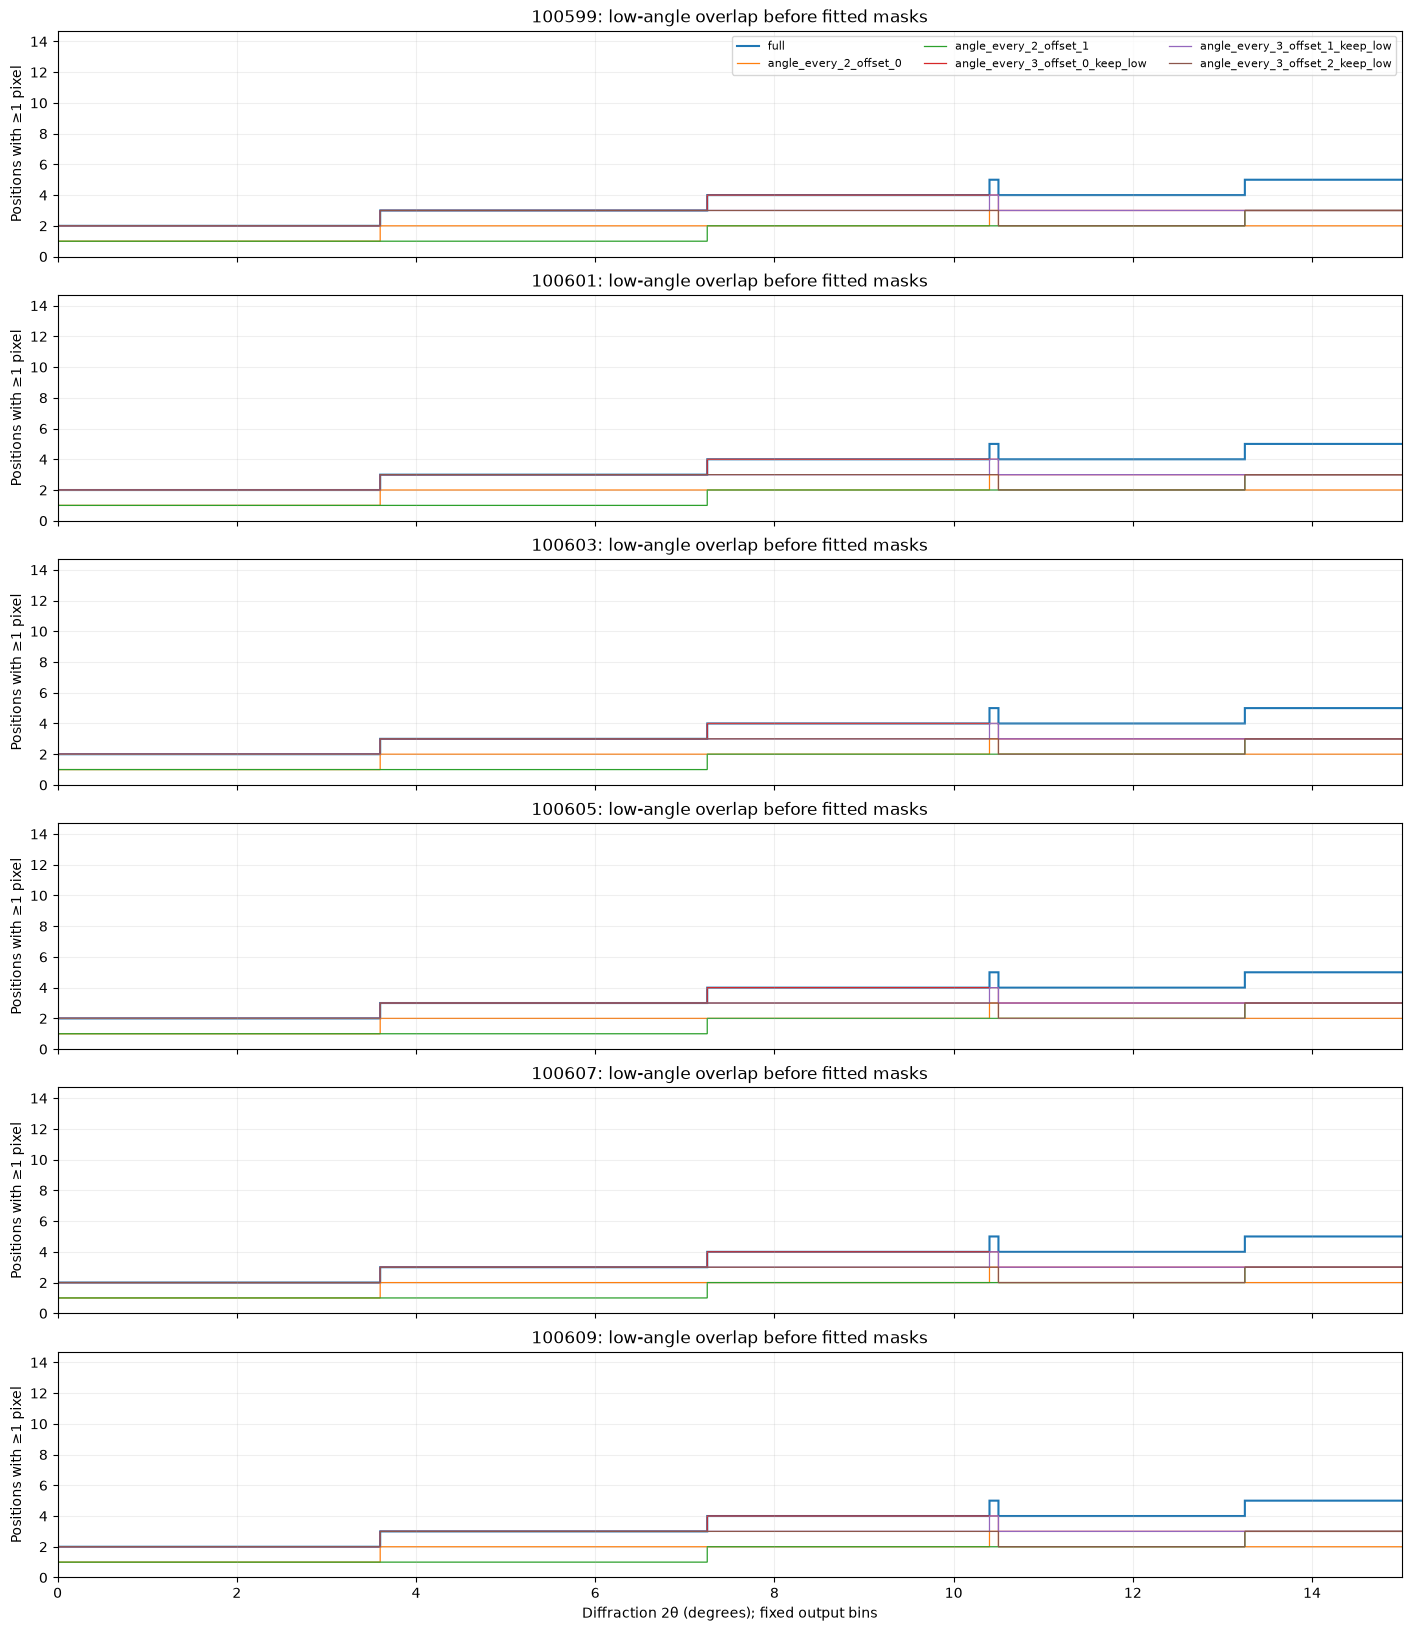

In [38]:
LOW_ANGLE_COVERAGE_DEG = (0., 15.)
LOW_MOTOR_LIMIT_DEG = 15.
GEOMETRY_MIN_PIXELS = 1
angular_cuts = [cut for cut in CUTS if cut.name == 'full' or cut.angle_stride > 1]
geometry_by_scan, geometry_rows, motor_spacing_rows = {}, [], []
low_bins = ((THETA_CENTRES >= LOW_ANGLE_COVERAGE_DEG[0])
            & (THETA_CENTRES < LOW_ANGLE_COVERAGE_DEG[1]))
for number in SCAN_NUMBERS:
    scan, calibration, groups = scans[number], calibrations[number], groups_by_scan[number]
    model = workflow.PhysicalModel(GEOMETRY_CONFIG, scan, POLARIZATION_FACTOR, SENSOR_DENSITY_G_CM3)
    coverage = short.geometry_coverage(scan, calibration, model, groups,
                                       angular_cuts, THETA_EDGES, ANGLE_TOLERANCE_DEG)
    geometry_by_scan[number] = coverage
    reference_ok = coverage['full']['pixels'] >= GEOMETRY_MIN_PIXELS
    for cut in angular_cuts:
        selection = short.select_groups(scan.angles, groups, cut, ANGLE_TOLERANCE_DEG)
        motor = np.array([scan.angles[m].mean() for m in selection.values()])
        spacings = np.diff(motor)
        low_spacings = spacings[motor[:-1] < LOW_MOTOR_LIMIT_DEG]
        motor_spacing_rows.append({'scan': number, 'cut': cut.name,
            'first_motor_deg': motor[0], 'last_motor_deg': motor[-1],
            'min_motor_step_deg': spacings.min() if spacings.size else np.nan,
            'max_motor_step_deg': spacings.max() if spacings.size else np.nan,
            'max_low_motor_step_deg': low_spacings.max() if low_spacings.size else np.nan})
        candidate_ok = coverage[cut.name]['pixels'] >= GEOMETRY_MIN_PIXELS
        for window, window_mask in [('all', np.ones(len(low_bins), bool)), ('low', low_bins)]:
            eligible = reference_ok & window_mask
            lost = eligible & ~candidate_ok
            gaps = short.missing_intervals(eligible, candidate_ok, THETA_EDGES)
            n = int(eligible.sum())
            geometry_rows.append({'scan': number, 'cut': cut.name, 'window': window,
                'reference_bins': n, 'lost_bins': int(lost.sum()),
                'coverage_fraction': 1 - lost.sum() / n if n else np.nan,
                'bins_with_two_positions': int(np.count_nonzero(
                    eligible & (coverage[cut.name]['positions'] >= 2))),
                'largest_gap_deg': max((b - a for a, b in gaps), default=0.),
                'lost_intervals_deg': gaps})
    del model
motor_spacings = pd.DataFrame(motor_spacing_rows)
geometry_audit = pd.DataFrame(geometry_rows)
display(motor_spacings.round(5))
display(geometry_audit[geometry_audit['window'] == 'low'])
if geometry_audit['lost_bins'].any():
    print('WARNING: some angle cuts lose full-reference coverage. Inspect gaps before accepting them.')

fig, axes = plt.subplots(len(SCAN_NUMBERS), 1, figsize=(14, 2.7 * len(SCAN_NUMBERS)),
                         sharex=True, squeeze=False, layout='constrained')
for axis, number in zip(axes.flat, SCAN_NUMBERS):
    coverage = geometry_by_scan[number]
    for cut in angular_cuts:
        if cut.frame_fraction != 1:
            continue
        axis.stairs(coverage[cut.name]['positions'], THETA_EDGES, label=cut.name,
                    lw=1.5 if cut.name == 'full' else 0.9)
    axis.set(title=f'{number}: low-angle overlap before fitted masks', ylabel='Positions with ≥1 pixel',
             xlim=LOW_ANGLE_COVERAGE_DEG)
    axis.set_ylim(bottom=0)
    axis.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8, ncol=3)
axes[-1, 0].set_xlabel('Diffraction 2θ (degrees); fixed output bins')
plt.show()

## 3. Independently fit every subset, integrate and export its correction

Set `RUN_INTEGRATIONS=True` in Cell 2 after checking the plan. Each cut rereads only its selected original frames, builds temporary summed group images, sums I0 and recomputes unweighted mean motor angles. Invalid/negative/saturated constituents reject the subset's pixel. Temporary detector sums are removed after the cut. There is a separate fit for every cut, including `full`.

The fitter starts from unity. Only native detector and boundary masks enter the cache; each subset learns its own pixel/sensor divisors, fitted bad pixels and source gains. Nothing is seeded from the long-scan map. Source gains apply only to their own subset, controlled by `APPLY_SELF_FITTED_SOURCE_GAINS`.

Each successful scan/cut directory contains a new correction HDF5 with `corrections/combined_divisor`, component maps, fitted mask, observation diagnostics, source gains and fit history; a pattern HDF5 with Poisson sigmas; and a manifest of original retained frame indices and its XY path. **XY exports are collected separately in the run's dedicated `xy` directory.** No previous correction file is required; geometry calibration is still required. Nothing is overwritten.

Angular coverage alone does not ensure enough repeated-pixel information to fit eight sensor regions with `minimum_observations=8`. Failed cuts are reported in `fit_summary`, never replaced by an old map or silently relaxed thresholds. A full-reference failure aborts the run. Successful fit status does not establish convergence/accuracy: inspect gain changes, support, maps and pattern differences. Held-out validation is not run by this batch.

### Dedicated XY directory, naming and format

**All XY files for all six scans and all successful subsets are collected together in `RUN_DIRECTORY / 'xy'`.** This directory contains only XY files. Correction HDF5, pattern HDF5 and manifests stay in their individual scan/subset directories. The fit-summary CSV and each manifest record the corresponding XY path. Existing outputs are never overwritten.

The XY basename includes scan, subset and whether fitted source gains were applied:

- `i15-1-100599__full__gi_applied__self_corrected_2theta.xy`
- `i15-1-100599__first_22__gi_applied__self_corrected_2theta.xy`
- `i15-1-100599__first_22__gi_unapplied__self_corrected_2theta.xy`
- `i15-1-100599__angle_every_3_offset_2_keep_low__gi_applied__self_corrected_2theta.xy`

`APPLY_SELF_FITTED_SOURCE_GAINS=True` selects `gi_applied`; `False` selects `gi_unapplied`. This controls application during integration, not whether gains are estimated during fitting (`FIT_SETTINGS['fit_frame_gains']`). Rerun Cell 2 to reload the helper and create a fresh timestamped run directory for each run.

Whitespace-separated ASCII: comment header `# 2theta_deg intensity`, then **two numerical columns**: diffraction 2θ in degrees and self-corrected normalized intensity. No background subtraction or extra rescaling. Only supported bins are exported: existing bin centres keep the fixed output step, but gaps can skip centres. The companion HDF5 retains the complete bin grid, sigmas, coverage and applied-gain flag; the correction HDF5 holds the newly fitted divisor. No XY is produced for a failed fit.

In [39]:
# pyFAI expands the radial endpoint by approximately one float32 epsilon.
# Allow that numerical padding, not a change in the requested integration grid.
AXIS_ATOL_DEG = 2 * np.finfo(np.float32).eps * max(1., abs(THETA_RANGE[1]))
STEP_ATOL_DEG = 2 * np.finfo(np.float32).eps * TWO_THETA_STEP_DEG
patterns_by_scan, metric_rows, fit_rows = {}, [], []
XY_DIRECTORY = RUN_DIRECTORY / 'xy'
if RUN_INTEGRATIONS:
    if WRITE_OUTPUTS:
        if RUN_DIRECTORY.exists():
            raise FileExistsError('Run directory already exists (possibly from an interrupted run). '
                                  'Rerun Cell 2 to create a fresh run directory; existing exports are preserved.')
        RUN_DIRECTORY.mkdir(parents=True, exist_ok=False)
        XY_DIRECTORY.mkdir(exist_ok=False)
        plan.to_csv(RUN_DIRECTORY / 'selection_plan.csv', index=False, mode='x')
        print('All XY exports:', XY_DIRECTORY)
    start = time.perf_counter()
    for number in SCAN_NUMBERS:
        scan, groups = scans[number], groups_by_scan[number]
        patterns = {}
        full_divisor, full_observed, full_mask = None, None, None
        for cut in CUTS:
            print(f'\n{number} / {cut.name}: independent fresh fit')
            model = workflow.PhysicalModel(GEOMETRY_CONFIG, scan,
                                           POLARIZATION_FACTOR, SENSOR_DENSITY_G_CM3)
            destination = RUN_DIRECTORY / str(number) / cut.name if WRITE_OUTPUTS else None
            try:
                experiment = short.self_calibrate_cut(
                    scan, model, groups, cut, FIT_SETTINGS, THETA_RANGE,
                    npt=THETA_NPT, saturation=RAW_SATURATION, tolerance=ANGLE_TOLERANCE_DEG,
                    apply_source_gains=APPLY_SELF_FITTED_SOURCE_GAINS,
                    output_directory=destination,
                    xy_directory=XY_DIRECTORY if WRITE_OUTPUTS else None)
            except ValueError as error:
                fit_rows.append({'scan': scan.path.stem, 'cut': cut.name,
                                 'status': 'failed', 'error': str(error)})
                print('FIT FAILED:', error)
                if cut.name == 'full':
                    raise RuntimeError(f'{number}: full reference failed; cannot compare this scan') from error
                continue
            finally:
                del model
            pattern, fit = experiment['pattern'], experiment['fit']
            np.testing.assert_allclose(pattern['axis'], THETA_CENTRES, atol=AXIS_ATOL_DEG, rtol=0)
            np.testing.assert_allclose(np.diff(pattern['axis']), TWO_THETA_STEP_DEG,
                                       atol=STEP_ATOL_DEG, rtol=0)
            patterns[cut.name] = pattern
            fixed_mask = experiment['base_mask'] | fit['bad_pixel_mask']
            observed = fit['observations'] >= FIT_SETTINGS['minimum_observations']
            if cut.name == 'full':
                full_divisor = fit['combined_divisor'].copy()
                full_observed, full_mask = observed.copy(), fixed_mask.copy()
            common = observed & full_observed & ~fixed_mask & ~full_mask
            map_difference = (100 * np.sqrt(np.mean(np.log(
                fit['combined_divisor'][common] / full_divisor[common])**2))
                if common.any() else np.nan)
            fit_rows.append({'scan': scan.path.stem, 'cut': cut.name, 'status': 'ok', 'error': '',
                'fit_positions': len(fit['fit_indices']),
                'bad_pixels': int(fit['bad_pixel_mask'].sum()),
                'pixels_observed_at_least_minimum': int(np.count_nonzero(observed & ~fixed_mask)),
                'common_map_pixels': int(common.sum()),
                'divisor_log_rms_vs_full_percent': float(map_difference),
                'last_max_log_gain_change': fit['history'][-1]['max_log_gain_change'],
                'calibration_path': str(experiment['calibration_path']) if WRITE_OUTPUTS else '',
                'xy_path': str(experiment['xy_path']) if WRITE_OUTPUTS else ''})
            for interval_name, interval in METRIC_INTERVALS.items():
                metric_rows.append({'scan': scan.path.stem, 'cut': cut.name, 'interval': interval_name,
                    **short.compare_patterns(patterns['full'], pattern, interval, MIN_PIXEL_SPLIT_COUNT)})
            del fit, experiment
        patterns_by_scan[number] = patterns
    metrics = pd.DataFrame(metric_rows).merge(plan, on=['scan', 'cut'], validate='many_to_one')
    fit_summary = pd.DataFrame(fit_rows).merge(plan, on=['scan', 'cut'], validate='one_to_one')
    if WRITE_OUTPUTS:
        metrics.to_csv(RUN_DIRECTORY / 'comparison_metrics.csv', index=False, mode='x')
        fit_summary.to_csv(RUN_DIRECTORY / 'fit_summary.csv', index=False, mode='x')
    display(fit_summary)
    display(metrics)
    print('Processing elapsed (minutes, not simulated acquisition time):', (time.perf_counter() - start) / 60)
else:
    metrics, fit_summary = pd.DataFrame(), pd.DataFrame()
    print('Preview only. Enable RUN_INTEGRATIONS in Cell 2 to fit each subset and export its divisor.')

All XY exports: /dls/science/users/fer45166/eiger-correction/outputs/self_fit_short_scan_20261028_175206_907057/xy

100599 / full: independent fresh fit
{'iteration': 1, 'rejected_percent': np.float64(0.0), 'max_log_gain_change': 0.16522500060808226}
{'iteration': 2, 'rejected_percent': np.float64(0.0), 'max_log_gain_change': 0.012589413007909556}
{'iteration': 3, 'rejected_percent': np.float64(0.012799763376221393), 'max_log_gain_change': 0.15356435667103352}
{'iteration': 4, 'rejected_percent': np.float64(0.013268428430680273), 'max_log_gain_change': 0.149929964715549}
{'iteration': 5, 'rejected_percent': np.float64(0.013330917104608124), 'max_log_gain_change': 0.0003355879740201285}
{'iteration': 6, 'rejected_percent': np.float64(0.013320502325620149), 'max_log_gain_change': 0.00015333366734288957}
{'iteration': 7, 'rejected_percent': np.float64(0.013320502325620149), 'max_log_gain_change': 7.06422417448161e-05}
{'iteration': 8, 'rejected_percent': np.float64(0.013330917104608124), 

,scan,cut,status,error,fit_positions,bad_pixels,pixels_observed_at_least_minimum,common_map_pixels,divisor_log_rms_vs_full_percent,last_max_log_gain_change,calibration_path,xy_path,groups,frames,frame_fraction,i0_fraction,motor_min_deg,motor_max_deg,full_wall_minutes,proportional_time_proxy_minutes
0,i15-1-100599,full,ok,,29.0,71.0,508942.0,508942.0,0.000000,0.000007,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,41,3608,1.000000,1.000000,0.0,80.000030,62.900267,62.900267
1,i15-1-100599,first_44,ok,,29.0,56.0,508957.0,508942.0,0.313582,0.000007,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,41,1804,0.500000,0.499967,0.0,80.000030,62.900267,31.450133
2,i15-1-100599,first_22,ok,,29.0,43.0,508970.0,508942.0,0.539702,0.000010,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,41,902,0.250000,0.249979,0.0,80.000030,62.900267,15.725067
3,i15-1-100599,first_11,ok,,29.0,33.0,508980.0,508942.0,0.812514,0.000015,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,41,451,0.125000,0.125005,0.0,79.999975,62.900267,7.862533
4,i15-1-100599,angle_every_2_offset_0,ok,,14.0,74.0,508939.0,508939.0,0.312776,0.000010,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,21,1848,0.512195,0.512213,0.0,80.000030,62.900267,32.217210
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,i15-1-100609,angle_every_3_offset_2_keep_low,failed,Sensor 1 has too few repeated pixel observatio...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15,1320,0.365854,0.365977,0.0,77.575405,62.854767,22.995646
74,i15-1-100609,motor_stop_70,ok,,28.0,101.0,508912.0,508912.0,0.008442,0.001001,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,33,2904,0.804878,0.805005,0.0,69.975180,62.854767,50.590422
75,i15-1-100609,motor_stop_60,ok,,20.0,101.0,508912.0,508912.0,0.109216,0.000031,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,25,2200,0.609756,0.609685,0.0,58.881881,62.854767,38.326077
76,i15-1-100609,angle_every_2_first_44,ok,,14.0,88.0,508925.0,508912.0,0.345136,0.003387,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,21,924,0.256098,0.256110,0.0,79.999975,62.854767,16.096952


,scan,cut,interval,reference_bins,common_bins,coverage_fraction,missing_reference_bins,relative_l2_percent,median_bias_percent,shape_log_rms_percent,median_sigma_ratio,max_supported_2theta_deg,groups,frames,frame_fraction,i0_fraction,motor_min_deg,motor_max_deg,full_wall_minutes,proportional_time_proxy_minutes
0,i15-1-100599,full,all,1742,1742,1.0,0,0.000000,0.000000,0.000000,1.000000,87.125010,41,3608,1.000000,1.000000,0.0,80.000030,62.900267,62.900267
1,i15-1-100599,full,low,599,599,1.0,0,0.000000,0.000000,0.000000,1.000000,29.975004,41,3608,1.000000,1.000000,0.0,80.000030,62.900267,62.900267
2,i15-1-100599,full,middle,600,600,1.0,0,0.000000,0.000000,0.000000,1.000000,59.975007,41,3608,1.000000,1.000000,0.0,80.000030,62.900267,62.900267
3,i15-1-100599,full,high,543,543,1.0,0,0.000000,0.000000,0.000000,1.000000,87.125010,41,3608,1.000000,1.000000,0.0,80.000030,62.900267,62.900267
4,i15-1-100599,first_44,all,1742,1742,1.0,0,0.021996,0.014999,0.023745,1.414360,87.125010,41,1804,0.500000,0.499967,0.0,80.000030,62.900267,31.450133
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,i15-1-100609,angle_every_2_first_44,high,543,543,1.0,0,0.054346,-0.027768,0.049051,1.987929,87.125010,21,924,0.256098,0.256110,0.0,79.999975,62.854767,16.096952
236,i15-1-100609,spread_22,all,1742,1742,1.0,0,0.005947,0.004639,0.017848,2.000041,87.125010,41,902,0.250000,0.250002,0.0,80.000030,62.854767,15.713692
237,i15-1-100609,spread_22,low,599,599,1.0,0,0.005746,0.001849,0.021786,2.000006,29.975004,41,902,0.250000,0.250002,0.0,80.000030,62.854767,15.713692
238,i15-1-100609,spread_22,middle,600,600,1.0,0,0.012289,0.003100,0.012171,2.000013,59.975007,41,902,0.250000,0.250002,0.0,80.000030,62.854767,15.713692


Processing elapsed (minutes, not simulated acquisition time): 46.83931765899955


In [40]:
# Actual post-integration low-angle audit: no gap filling or resampling.
actual_gap_rows = []
for number, patterns in patterns_by_scan.items():
    full = patterns['full']
    low = ((full['axis'] >= LOW_ANGLE_COVERAGE_DEG[0])
           & (full['axis'] < LOW_ANGLE_COVERAGE_DEG[1]))
    eligible = (low & (full['accumulators'][1] > 0)
                & (full['accumulators'][3] >= MIN_PIXEL_SPLIT_COUNT)
                & np.isfinite(full['intensity']))
    for name, pattern in patterns.items():
        supported = ((pattern['accumulators'][1] > 0)
                     & (pattern['accumulators'][3] >= MIN_PIXEL_SPLIT_COUNT)
                     & np.isfinite(pattern['intensity']))
        gaps = short.missing_intervals(eligible, supported, THETA_EDGES)
        n = int(eligible.sum())
        lost = int(np.count_nonzero(eligible & ~supported))
        actual_gap_rows.append({'scan': number, 'cut': name,
            'reference_low_bins': n, 'lost_low_bins': lost,
            'low_coverage_fraction': 1 - lost / n if n else np.nan,
            'largest_low_gap_deg': max((b - a for a, b in gaps), default=0.),
            'lost_low_intervals_deg': gaps})
actual_low_coverage = pd.DataFrame(actual_gap_rows)
if not actual_low_coverage.empty:
    display(actual_low_coverage)
    if actual_low_coverage['lost_low_bins'].any():
        print('WARNING: actual low-angle coverage is missing for some cuts; '
              'small common-bin residuals do not validate those cuts.')
    if WRITE_OUTPUTS:
        geometry_audit.to_csv(RUN_DIRECTORY / 'geometry_coverage.csv', index=False, mode='x')
        motor_spacings.to_csv(RUN_DIRECTORY / 'motor_spacings.csv', index=False, mode='x')
        actual_low_coverage.to_csv(RUN_DIRECTORY / 'actual_low_angle_coverage.csv', index=False, mode='x')
else:
    print('Actual low-angle audit will run after integrations are enabled.')

,scan,cut,reference_low_bins,lost_low_bins,low_coverage_fraction,largest_low_gap_deg,lost_low_intervals_deg
0,100599,full,299,0,1.000000,0.00,[]
1,100599,first_44,299,0,1.000000,0.00,[]
2,100599,first_22,299,0,1.000000,0.00,[]
3,100599,first_11,299,0,1.000000,0.00,[]
4,100599,angle_every_2_offset_0,299,1,0.996656,0.05,"[(0.05, 0.1)]"
5,100599,angle_every_2_offset_1,299,1,0.996656,0.05,"[(0.05, 0.1)]"
6,100599,motor_stop_70,299,0,1.000000,0.00,[]
7,100599,motor_stop_60,299,0,1.000000,0.00,[]
8,100599,angle_every_2_first_44,299,1,0.996656,0.05,"[(0.05, 0.1)]"
9,100599,spread_22,299,0,1.000000,0.00,[]


## 4. Compare coverage, bias, shape and counting noise

Metrics are computed within fixed low/middle/high diffraction-angle windows as well as over all bins. Bins must have nonzero normalization and the configured minimum fractional pixel-splitting count; missing reference bins are reported, **not interpolated or hidden**. The additional post-integration audit above resolves individual gaps in the configurable 0–15° low-angle window.

- **Coverage fraction:** fraction of eligible full-reference bins retained by a cut. Inspect this before accepting a small residual.
- **Relative L2 (%):** $100\sqrt{\sum(I_s-I_f)^2/\sum I_f^2}$ on common bins, no intensity rescaling. Strong peaks dominate; this is not weighted crystallographic $R_{wp}$.
- **Median bias (%):** $100[\exp(\mathrm{median}(\log(I_s/I_f)))-1]$, positive-intensity bins only.
- **Shape log RMS (%):** centered log-ratio RMS on positive common bins. Separates shape scatter from global scale but does not modify any pattern.
- **Median sigma ratio:** propagated raw-Poisson uncertainty ratio. At unchanged angular sampling and stable flux, roughly $1/\sqrt{f}$ is a useful exposure-only expectation, not a significance test.

Plots compare each material/scan to **its own full reference**, never average different materials. For deciding a new collection strategy, agree tolerances for coverage, peak shapes/areas and weak high-angle features first. Offset sensitivity for every-2nd/every-3rd **nonuniform** motor positions is a warning about insufficient overlap. For PDF work, also process each exported XY using identical PDFgetX3 settings; lost Q range changes real-space resolution (approximately $\Delta r\simeq\pi/Q_{\max}$). These diffraction-pattern metrics alone do not certify PDF quality.

No successful pattern for: ['angle_every_3_offset_2_keep_low'] — inspect fit_summary


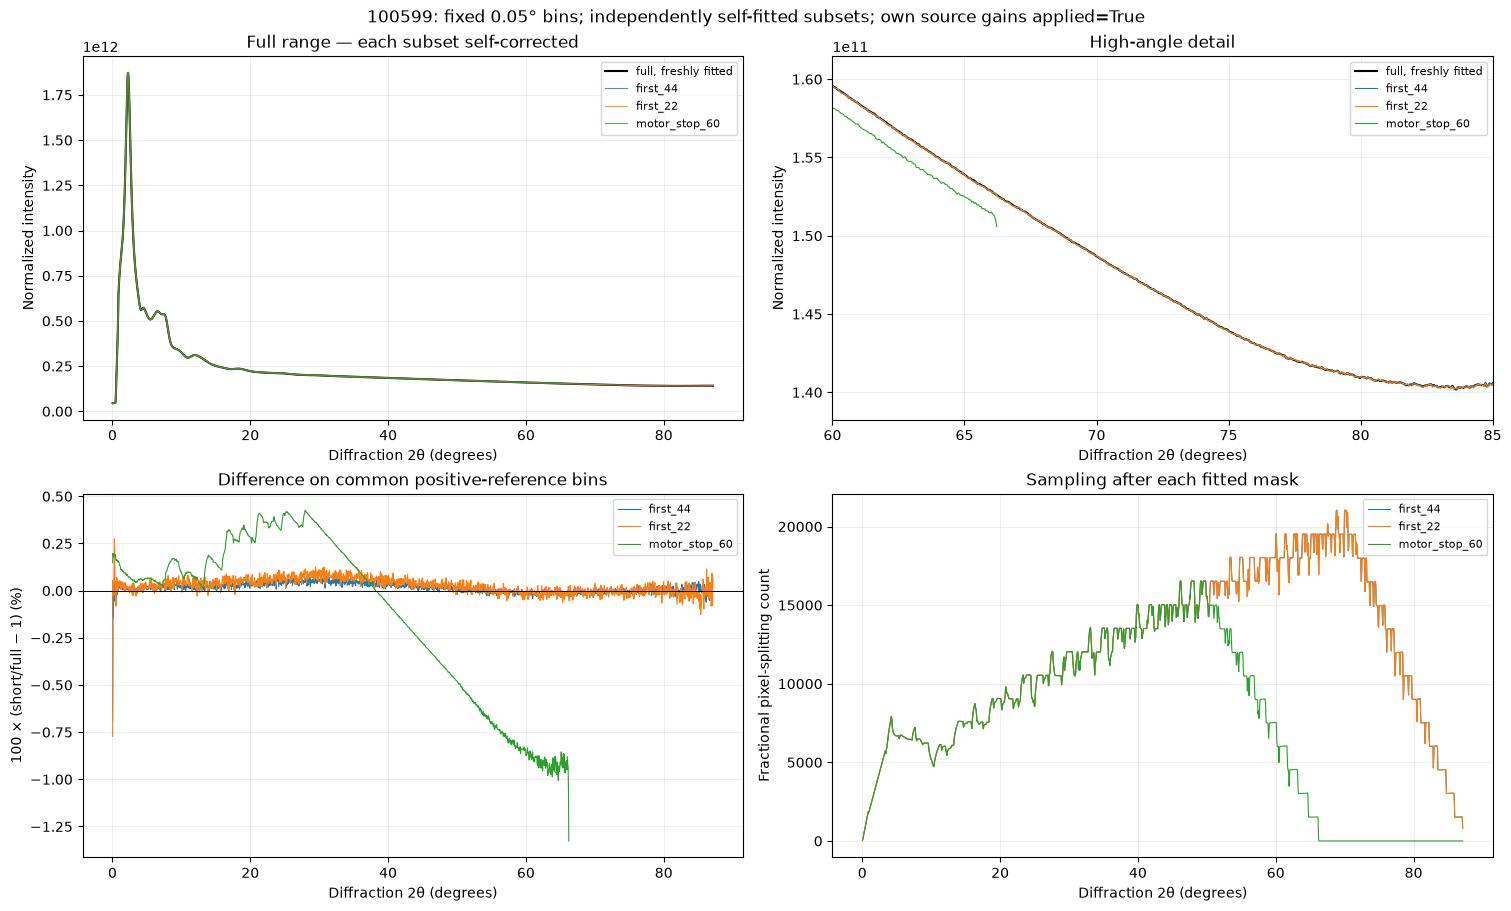

,scan,cut,status,error,fit_positions,bad_pixels,pixels_observed_at_least_minimum,common_map_pixels,divisor_log_rms_vs_full_percent,last_max_log_gain_change,calibration_path,xy_path,groups,frames,frame_fraction,i0_fraction,motor_min_deg,motor_max_deg,full_wall_minutes,proportional_time_proxy_minutes
0,i15-1-100599,full,ok,,29.0,71.0,508942.0,508942.0,0.000000,0.000007,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,41,3608,1.000000,1.000000,0.0,80.000030,62.900267,62.900267
1,i15-1-100599,first_44,ok,,29.0,56.0,508957.0,508942.0,0.313582,0.000007,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,41,1804,0.500000,0.499967,0.0,80.000030,62.900267,31.450133
2,i15-1-100599,first_22,ok,,29.0,43.0,508970.0,508942.0,0.539702,0.000010,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,41,902,0.250000,0.249979,0.0,80.000030,62.900267,15.725067
3,i15-1-100599,first_11,ok,,29.0,33.0,508980.0,508942.0,0.812514,0.000015,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,41,451,0.125000,0.125005,0.0,79.999975,62.900267,7.862533
4,i15-1-100599,angle_every_2_offset_0,ok,,14.0,74.0,508939.0,508939.0,0.312776,0.000010,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,21,1848,0.512195,0.512213,0.0,80.000030,62.900267,32.217210
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,i15-1-100609,angle_every_3_offset_2_keep_low,failed,Sensor 1 has too few repeated pixel observatio...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15,1320,0.365854,0.365977,0.0,77.575405,62.854767,22.995646
74,i15-1-100609,motor_stop_70,ok,,28.0,101.0,508912.0,508912.0,0.008442,0.001001,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,33,2904,0.804878,0.805005,0.0,69.975180,62.854767,50.590422
75,i15-1-100609,motor_stop_60,ok,,20.0,101.0,508912.0,508912.0,0.109216,0.000031,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,25,2200,0.609756,0.609685,0.0,58.881881,62.854767,38.326077
76,i15-1-100609,angle_every_2_first_44,ok,,14.0,88.0,508925.0,508912.0,0.345136,0.003387,/dls/science/users/fer45166/eiger-correction/o...,/dls/science/users/fer45166/eiger-correction/o...,21,924,0.256098,0.256110,0.0,79.999975,62.854767,16.096952


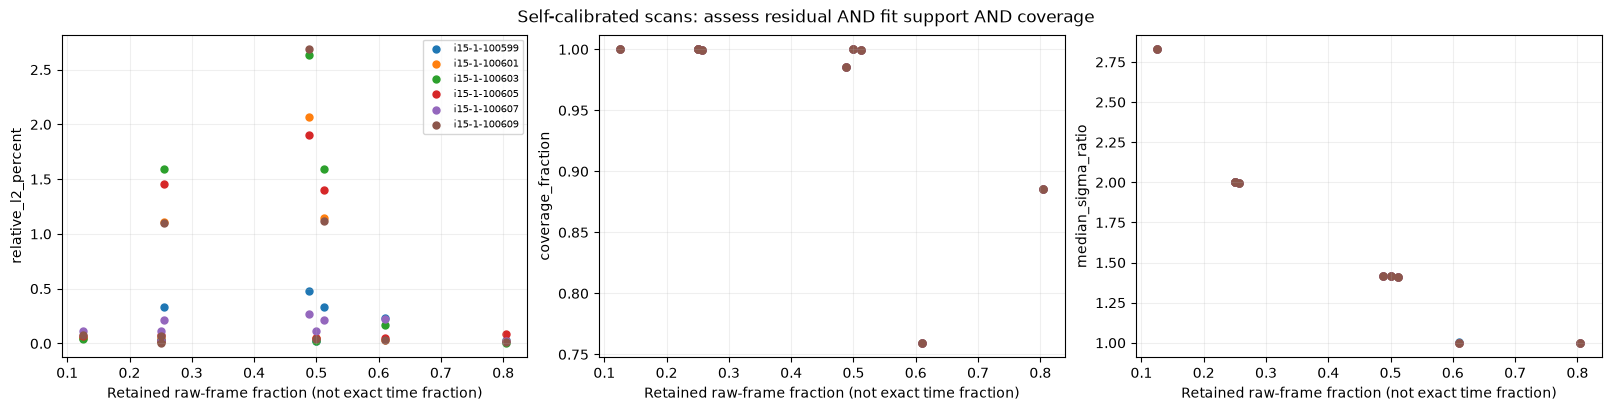

In [41]:
PLOT_SCAN = 100599
PLOT_CUTS = ('first_44', 'first_22', 'angle_every_3_offset_2_keep_low', 'motor_stop_60')
ZOOM_DEG = (60., 85.)
if PLOT_SCAN in patterns_by_scan:
    patterns = patterns_by_scan[PLOT_SCAN]
    full = patterns['full']
    available = [name for name in PLOT_CUTS if name in patterns]
    missing = [name for name in PLOT_CUTS if name not in patterns]
    if missing:
        print('No successful pattern for:', missing, '— inspect fit_summary')
    fig, axes = plt.subplots(2, 2, figsize=(15, 9), layout='constrained')
    supported = full['accumulators'][1] > 0
    full_display = np.where(supported, full['intensity'], np.nan)
    axes[0, 0].plot(full['axis'], full_display, color='black', lw=1.5, label='full, freshly fitted')
    axes[0, 1].plot(full['axis'], full_display, color='black', lw=1.5, label='full, freshly fitted')
    for name in available:
        pattern = patterns[name]
        ok = (pattern['accumulators'][1] > 0) & np.isfinite(pattern['intensity'])
        y = np.where(ok, pattern['intensity'], np.nan)
        line, = axes[0, 0].plot(pattern['axis'], y, lw=0.8, alpha=0.8, label=name)
        axes[0, 1].plot(pattern['axis'], y, lw=0.8, color=line.get_color(), label=name)
        common = ok & supported & (full['intensity'] > 0)
        residual = np.full(len(y), np.nan)
        residual[common] = 100 * (y[common] / full['intensity'][common] - 1)
        axes[1, 0].plot(pattern['axis'], residual, lw=0.8, color=line.get_color(), label=name)
        axes[1, 1].plot(pattern['axis'], pattern['accumulators'][3],
                        lw=0.8, color=line.get_color(), label=name)
    axes[0, 0].set(title='Full range — each subset self-corrected', ylabel='Normalized intensity')
    axes[0, 1].set(title='High-angle detail', xlim=ZOOM_DEG, ylabel='Normalized intensity')
    zoom_values = np.concatenate([p['intensity'][(p['axis'] >= ZOOM_DEG[0]) &
        (p['axis'] <= ZOOM_DEG[1]) & (p['accumulators'][1] > 0)]
        for p in [full] + [patterns[name] for name in available]])
    zoom_values = zoom_values[np.isfinite(zoom_values)]
    if len(zoom_values):
        lo, hi = float(zoom_values.min()), float(zoom_values.max())
        margin = max((hi - lo) * 0.1, abs(hi) * 0.01, np.finfo(float).eps)
        axes[0, 1].set_ylim(lo - margin, hi + margin)
    axes[1, 0].axhline(0, color='black', lw=0.7)
    axes[1, 0].set(title='Difference on common positive-reference bins', ylabel='100 × (short/full − 1) (%)')
    axes[1, 1].set(title='Sampling after each fitted mask', ylabel='Fractional pixel-splitting count')
    for axis in axes.flat:
        axis.set_xlabel('Diffraction 2θ (degrees)')
        axis.grid(alpha=0.2)
        axis.legend(fontsize=8)
    fig.suptitle(f'{PLOT_SCAN}: fixed {TWO_THETA_STEP_DEG:g}° bins; independently self-fitted subsets; '
                 f'own source gains applied={APPLY_SELF_FITTED_SOURCE_GAINS}')
    plt.show()
else:
    print('Run self-calibration fits first to display pattern comparisons.')

if not fit_summary.empty:
    display(fit_summary)
if not metrics.empty:
    selected_metrics = metrics[(metrics['cut'] != 'full') & (metrics['interval'] == 'all')]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout='constrained')
    for scan_name, rows in selected_metrics.groupby('scan', sort=False):
        for axis, field in zip(axes, ('relative_l2_percent', 'coverage_fraction', 'median_sigma_ratio')):
            axis.scatter(rows['frame_fraction'], rows[field], label=scan_name, s=25)
            axis.set(xlabel='Retained raw-frame fraction (not exact time fraction)', ylabel=field)
            axis.grid(alpha=0.2)
    axes[0].legend(fontsize=7)
    fig.suptitle('Self-calibrated scans: assess residual AND fit support AND coverage')
    plt.show()